In [99]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib as jb   # pour sauvegarder les objets utilisés au déploiement

In [100]:
#suppression des warnings
import warnings
warnings.filterwarnings("ignore")

## Description des variables

Le jeu de données contient **5 861 voitures** décrites par **7 variables** : 6 variables explicatives et 1 variable cible (`Selling_Price`).

| Variable | Type | Description | Valeurs / plage observée |
|---|---|---|---|
| `Kms_Driven` | Numérique (continue) | Kilométrage parcouru par la voiture | 500 – 538 824 km (médiane ≈ 71 822) |
| `Present_Price` | Numérique (continue) | Prix actuel du modèle (même unité que la cible) | 0,32 – 102,66 (médiane ≈ 15,4) |
| `Fuel_Type` | Catégorielle | Type de carburant | `Petrol`, `Diesel`, `CNG` |
| `Seller_Type` | Catégorielle | Type de vendeur | `Dealer` (concessionnaire), `Individual` (particulier) |
| `Transmission` | Catégorielle | Type de boîte de vitesse | `Manual` (manuelle), `Automatic` (automatique) |
| `Age` | Numérique (discrète) | Âge de la voiture, en années | 2 – 22 ans (médiane = 8) |
| **`Selling_Price`** | Numérique (continue) | **Variable cible** : prix de vente de la voiture | 0,10 – 41,90 (médiane ≈ 9,05) |

In [101]:
# Import les données
df = pd.read_csv("Car_dataset.csv")
df.head()

,Kms_Driven,Present_Price,Fuel_Type,Seller_Type,Transmission,Age,Selling_Price
0,27000,5.59,Petrol,Dealer,Manual,6,3.35
1,43000,9.54,Diesel,Dealer,Manual,7,4.75
2,6900,9.85,Petrol,Dealer,Manual,3,7.25
3,5200,4.15,Petrol,Dealer,Manual,9,2.85
4,42450,6.87,Diesel,Dealer,Manual,6,4.60


In [102]:
# Dimension des données
df.shape

(5861, 7)

In [103]:
# Afficher les infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5861 entries, 0 to 5860
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Kms_Driven     5861 non-null   int64  
 1   Present_Price  5861 non-null   float64
 2   Fuel_Type      5861 non-null   str    
 3   Seller_Type    5861 non-null   str    
 4   Transmission   5861 non-null   str    
 5   Age            5861 non-null   int64  
 6   Selling_Price  5861 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 320.7 KB


### <font color = 'bisque'>Exploration et préparation des données

In [104]:
# sélection les variables quantitatives
quant_data = df.select_dtypes(include = "number")
quant_data.head()

,Kms_Driven,Present_Price,Age,Selling_Price
0,27000,5.59,6,3.35
1,43000,9.54,7,4.75
2,6900,9.85,3,7.25
3,5200,4.15,9,2.85
4,42450,6.87,6,4.60


In [105]:
# décrire les variables quantitatives
quant_data.describe()

,Kms_Driven,Present_Price,Age,Selling_Price
count,5861.000000,5861.000000,5861.000000,5861.000000
mean,75209.206108,16.869948,8.562532,10.196217
std,39198.500980,9.659501,3.099993,5.874282
min,500.000000,0.320000,2.000000,0.100000
25%,53822.000000,10.552438,6.000000,6.401756
50%,71822.000000,15.375776,8.000000,9.049277
75%,87820.000000,19.229938,10.000000,11.873727
max,538824.000000,102.661886,22.000000,41.903189


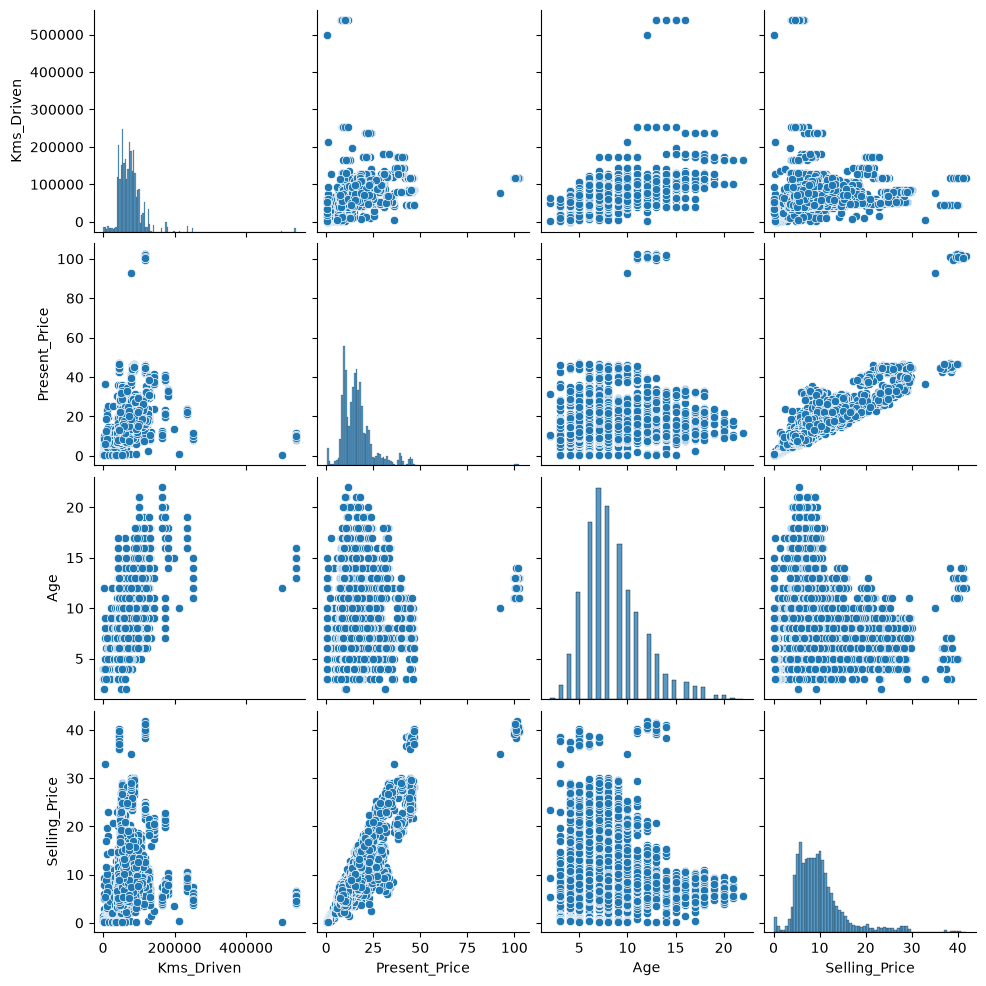

In [106]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

In [107]:
# Fonction permettant de visualiser les boxplots
def boxplot_func(col):
    fig = px.box(df,x = col)
    fig.show()

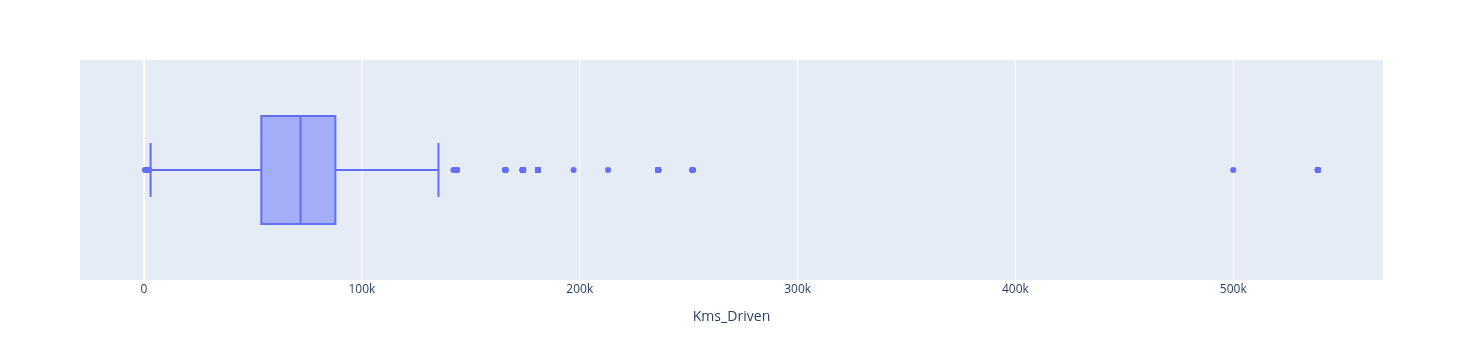

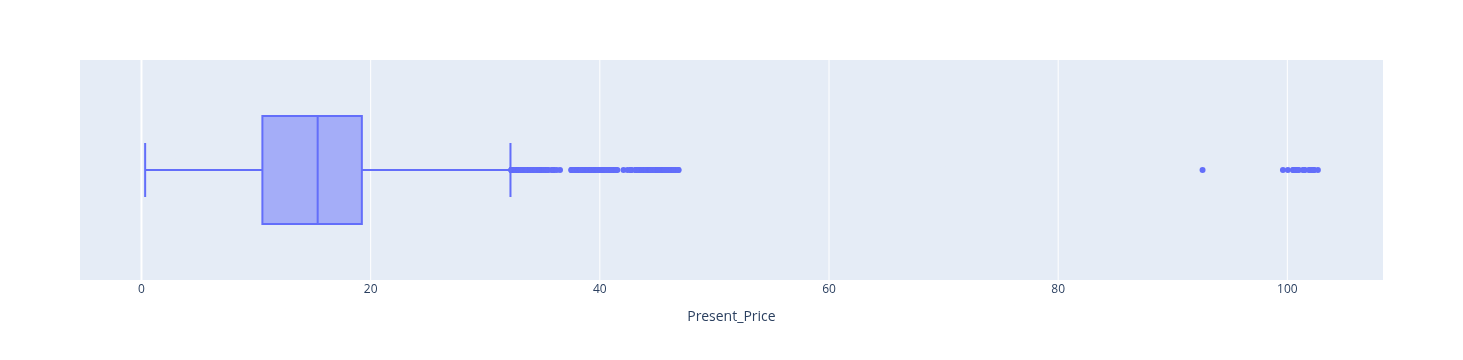

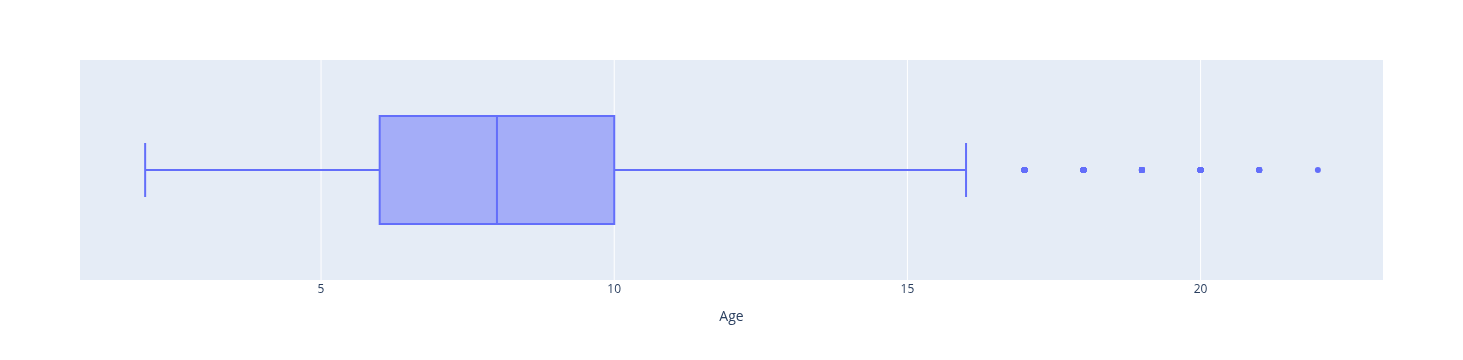

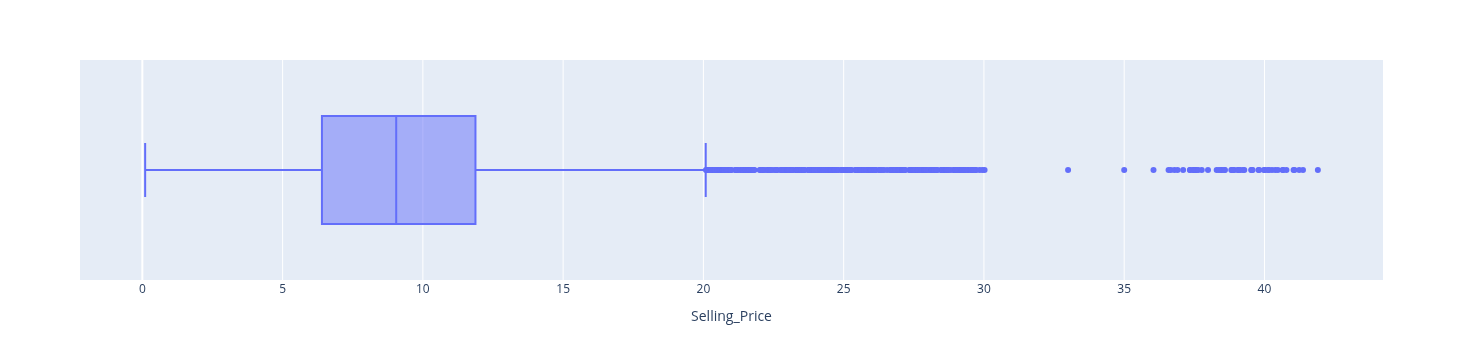

In [108]:
# Appliquer la fonctions boxplot_func
for col in quant_data.columns:
  boxplot_func(col)

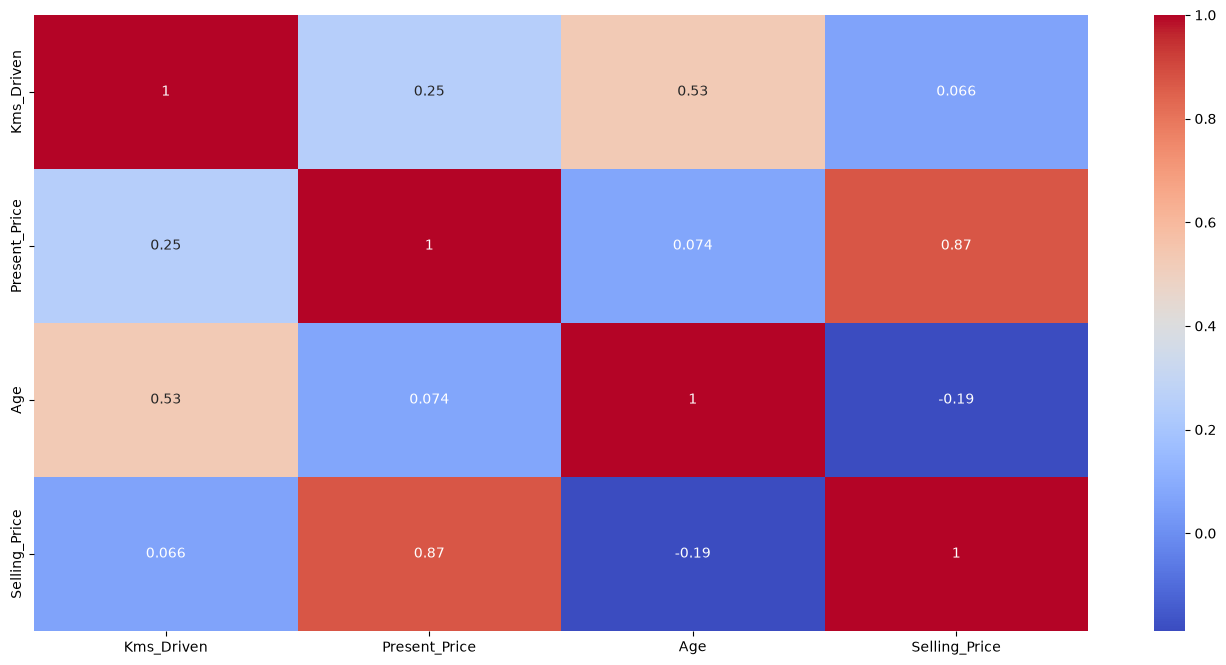

In [109]:
# Afficher la matrice de corrélation
plt.figure(figsize=(17,8))
sns.heatmap(quant_data.corr(), annot=True, cmap= "coolwarm")
plt.show()

In [110]:
# sélection les variables catégorielles
cat_data = df.select_dtypes(exclude = "number")

In [111]:
# Faire un describre
cat_data.describe()

,Fuel_Type,Seller_Type,Transmission
count,5861,5861,5861
unique,3,2,2
top,Petrol,Dealer,Automatic
freq,2743,3765,3007


In [112]:
# Fonction de visualisaion du counplot
def countplot_func(col):
    val = cat_data[col].value_counts()
    fig = px.bar(x = val.index, y = val.values,color = val.index.astype(str), text_auto = True)
    fig.show()

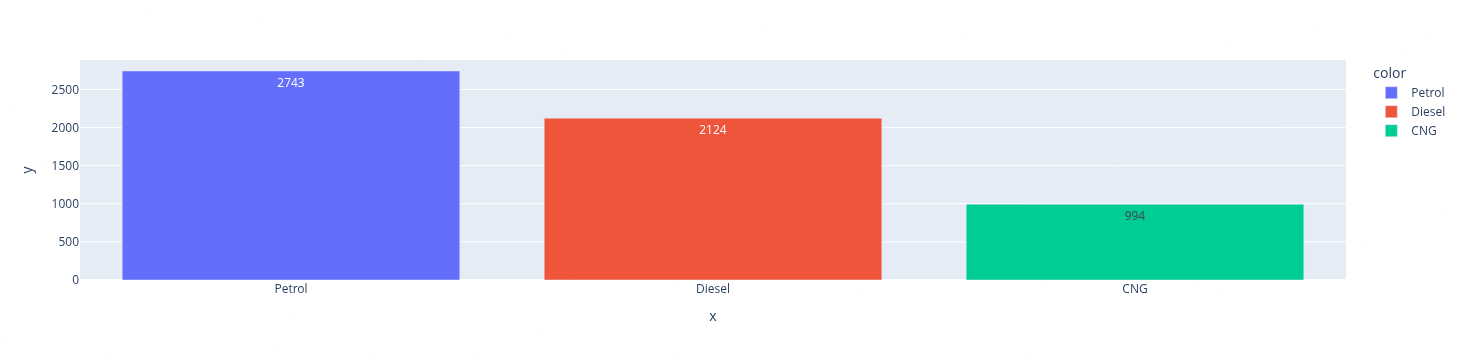

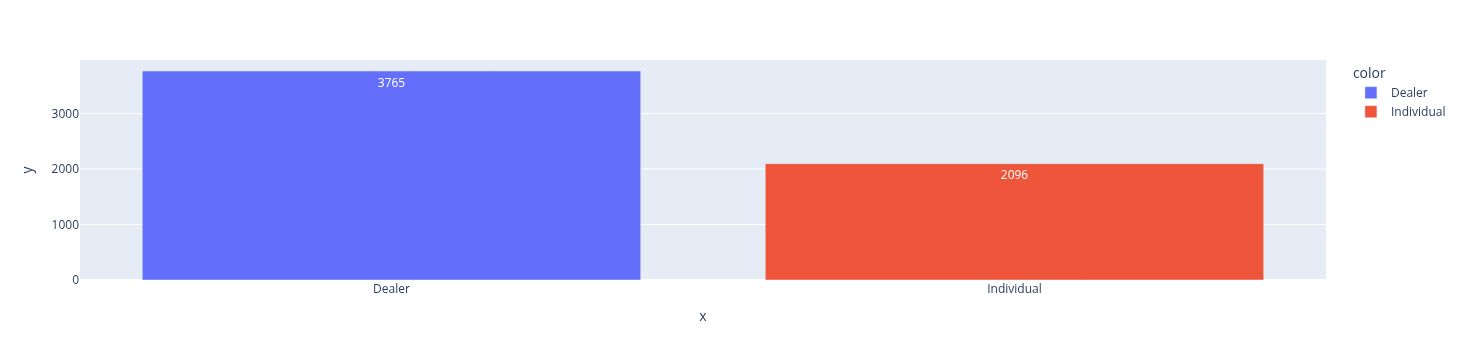

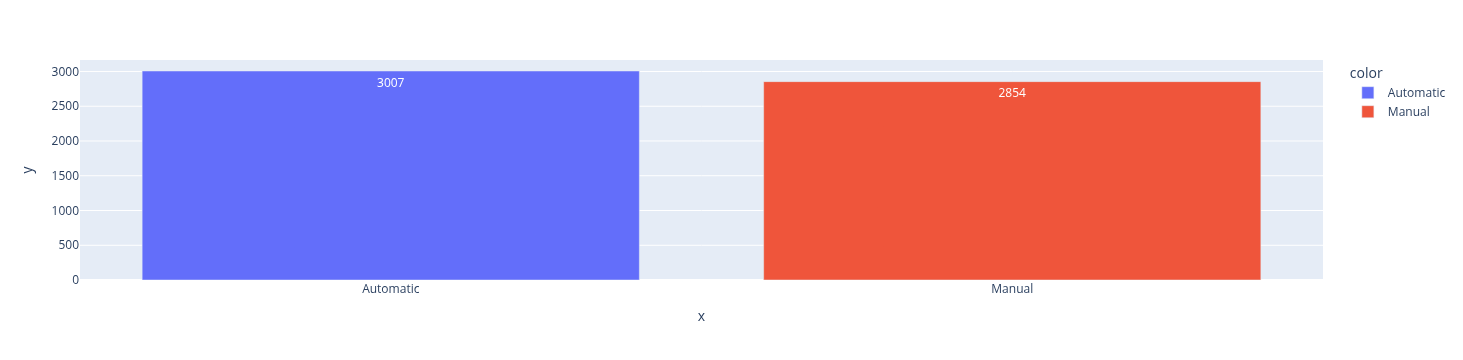

In [113]:
# Appliquer la fonction countplot_func
for col in cat_data:
    countplot_func(col)

In [114]:
# vérifier les valeurs manquantes (il n'y en a pas dans ce jeu de données)
df.isna().sum()

Kms_Driven       0
Present_Price    0
Fuel_Type        0
Seller_Type      0
Transmission     0
Age              0
Selling_Price    0
dtype: int64

In [115]:
# Imputation des valeurs manquantes des variables catégorielle en utilisant le mode
for col in cat_data.columns:
  df.fillna({col: df[col].mode()[0]}, inplace = True)

In [116]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib (listes déroulantes du déploiement)
uniques = {col: np.unique(df[col]).tolist() for col in cat_data.columns}
# sauvegarde
jb.dump(uniques, "./models/prix_voiture_uniques.joblib")
uniques['Fuel_Type']

['CNG', 'Diesel', 'Petrol']

In [117]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# Créer différents encodeurs pour les variables catégorielles
encoders = {}
for col in cat_data.columns:
  encoder = LabelEncoder()
  encoder.fit(df[col]) # le modèle prend le temps de reconnaitre les classes
  df[col] = encoder.transform(df[col]) # encoder les valeurs
  # rajouter l'encoder dans le dictionnaire encoders
  encoders[col] = encoder

In [118]:
# sauvegarde les encodeurs
jb.dump(encoders, "./models/prix_voiture_encoders.joblib")

['./models/prix_voiture_encoders.joblib']

In [120]:
from sklearn.impute import KNNImputer
# Imputation des valeurs manquantes des variables quantitatives
imputer = KNNImputer(n_neighbors=5)
df[:] = imputer.fit_transform(df)

In [121]:
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan # NaN
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [122]:
# Application du traitement valeurs aberantes
for col in quant_data :
    impute_func(df,col)

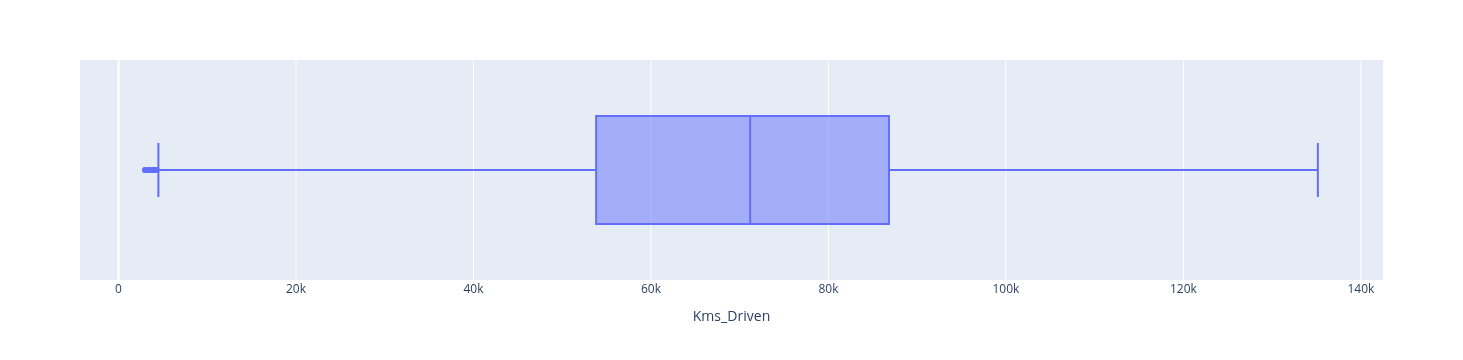

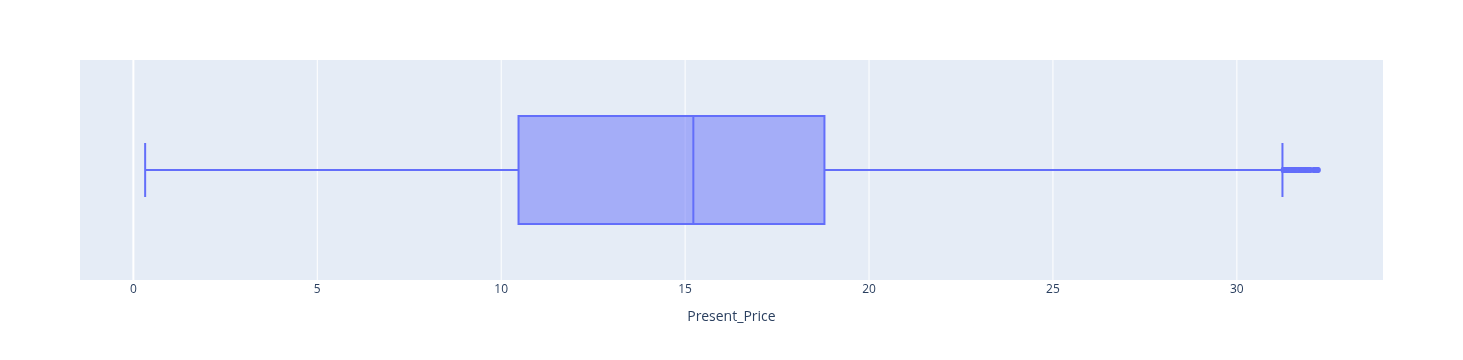

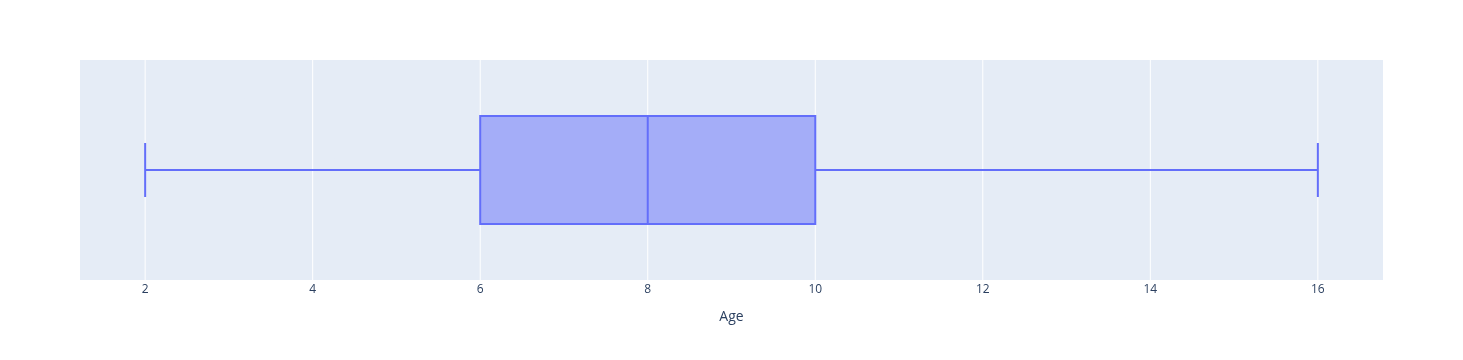

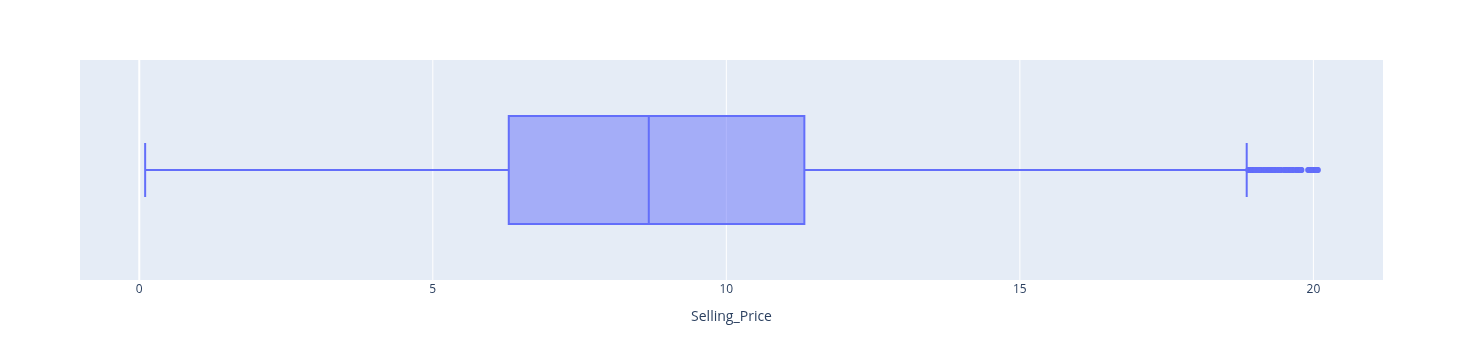

In [123]:
# réafficher les boxplots
for col in quant_data:
    boxplot_func(col)

In [124]:
# Fractionner les données (la variable cible Selling_Price est la dernière colonne)
x = df.iloc[:,:-1].values
y = df.iloc[:, -1].values

# ordre des variables explicatives (à respecter lors des prédictions)
features = df.columns[:-1].tolist()
jb.dump(features, "./models/prix_voiture_features.joblib")
features

['Kms_Driven',
 'Present_Price',
 'Fuel_Type',
 'Seller_Type',
 'Transmission',
 'Age']

In [125]:
from sklearn.model_selection import train_test_split
# Splitter les données en train, val et test
x_train, x_vt,y_train,y_vt = train_test_split(x,y , test_size = 0.2, random_state = 42)
# Splitter les données en val et test
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)

In [126]:
# importer RobustScaler
from sklearn.preprocessing import RobustScaler
# Normaliser x : le scaler est ajusté sur le train uniquement, puis appliqué à val et test
scaler = RobustScaler()
scaler.fit(x_train)
x_train = scaler.transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

In [127]:
# sauvegarde du scaler
jb.dump(scaler, "./models/prix_voiture_scaler.joblib")

['./models/prix_voiture_scaler.joblib']

In [128]:
# verfication par affichage
x_train[:5]

array([[ 0.81991455,  0.78986366,  1.        ,  0.        ,  0.        ,
         0.25      ],
       [ 1.36307991,  0.72865232,  0.        ,  0.        ,  1.        ,
         1.5       ],
       [ 0.091876  ,  0.18759382,  1.        ,  0.        ,  0.        ,
        -0.25      ],
       [-0.02112057,  0.34816522,  1.        ,  0.        ,  1.        ,
         0.25      ],
       [ 0.08064604, -0.71041927,  1.        ,  0.        ,  1.        ,
         0.75      ]])

### <font color = 'bisque'>Multiple Linear Regression

In [129]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression

# Validation croisée et figé
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params_lr = {
    'fit_intercept': [True, False],
    'positive': [True, False]
 }
# Initialisation du modèle
lr = LinearRegression()
# Initialisation du GridSearchCV
grid_lr = GridSearchCV(lr, params_lr, cv = cv)
# Lancer la recherche
grid_lr.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'fit_intercept': [True, False], 'positive': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosi

In [130]:
# Récupérer le modèle optimal en partant de gridsearch
lr_model = grid_lr.best_estimator_

#### <font color = 'teal'> Evaluation du Linear Regression<font>

In [131]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,root_mean_squared_error
# Calculer le R2 score et Mean Squarred Error
def evaluation(model):
  y_pred = model.predict(x_val)
  r2 = r2_score(y_val, y_pred)
  mse = mean_squared_error(y_val, y_pred)
  mae = mean_absolute_error(y_val, y_pred)
  rmse = root_mean_squared_error(y_val, y_pred)
  return r2, mse, mae, rmse

In [132]:
# evaluation
r2_lr, mse_lr, mae_lr, rmse_lr = evaluation(lr_model)
print(f"R2: {r2_lr}, mse: {mse_lr}, mae: {mae_lr}, rmse: {rmse_lr}")

R2: 0.6498369115217089, mse: 4.707610202914737, mae: 1.6185933422598946, rmse: 2.1697027913782887


### <font color = 'bisque'>Ridge Regression

In [133]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.linear_model import Ridge
# dictionnaire params
params_rr = {
    'fit_intercept': [True, False],
    'positive': [True, False],
    'alpha':np.logspace(-8,8, 100) #
 }
# Initialisation du modèle
rr = Ridge()
# Initialisation du GridSearchCV
grid_rr = GridSearchCV(rr, params_rr, cv = cv, n_jobs = -1)
# Lancer la recherche
grid_rr.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': array([1.0000...00000000e+08]), 'fit_intercept': [True, False], 'positive': [True, False]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, d

In [134]:
# Récupérer le modèle optimal en partant de gridsearch
rr_model = grid_rr.best_estimator_

#### <font color = 'teal'> Evaluation du Ridge<font>

In [135]:
# Evaluation le modèle
r2_rr, mse_rr, mae_rr, rmse_rr = evaluation(rr_model)
print(f"R2: {r2_rr}, mse: {mse_rr}, mae: {mae_rr}, rmse: {rmse_rr}")

R2: 0.6498319451651089, mse: 4.707676970863075, mae: 1.6196748899862772, rmse: 2.1697181777509895


### <font color = 'bisque'>Decision Tree Regressor<font>

In [136]:
# Recherche des paramètres optimaux du decision tree
from sklearn.tree import DecisionTreeRegressor
# Dictionaire des params
params_dt = {
    'max_depth':np.arange(1,30),
    'criterion':['squared_error', 'absolute_error']
}
# Initialisation du modèle
dt = DecisionTreeRegressor(random_state = 42)
# Initialisation du GridSearchCV
grid_dt = GridSearchCV(dt, params_dt, cv = cv, n_jobs = -1)
# Lancer la recherche
grid_dt.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['squared_error', 'absolute_error'], 'max_depth': array([ 1, 2..., 27, 28, 29])}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbos

In [137]:
# Récupérer le modèle optimal en partant de gridsearch
dt_model = grid_dt.best_estimator_

#### <font color = 'teal'> Evaluation du Decision Tree Regressor<font>

In [138]:
# Evaluation le modèle
r2_dt, mse_dt, mae_dt, rmse_dt = evaluation(dt_model)
print(f"R2: {r2_dt}, mse: {mse_dt}, mae: {mae_dt}, rmse: {rmse_dt}")

R2: 0.8338000152590459, mse: 2.2344009681057395, mae: 1.1037894761437956, rmse: 1.4947912791108127


### <font color = 'bisque'>Random Forest Regressor<font>

In [139]:
from sklearn.ensemble import RandomForestRegressor

# Dictionnaires des paramètres
params_rf = {
    'n_estimators':np.arange(10,100,10),
    'max_depth':np.arange(1,15)
}
# Initialisation du modèle
rf =  RandomForestRegressor(random_state = 42)
# Objet grid
grid_rf = GridSearchCV(rf, params_rf, cv=cv, n_jobs = -1)
# Lancer la recherche
grid_rf.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([ 1, 2..., 12, 13, 14]), 'n_estimators': array([10, 20..., 70, 80, 90])}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose 

In [140]:
# Récupérer le modèle optimal en partant de gridsearch
rf_model = grid_rf.best_estimator_

#### <font color = 'teal'> Evaluation du Random Forest<font>

In [141]:
# Evaluation le modèle
r2_rf, mse_rf, mae_rf, rmse_rf = evaluation(rf_model)
print(f"R2: {r2_rf}, mse: {mse_rf}, mae: {mae_rf}, rmse: {rmse_rf}")

R2: 0.8787005625353455, mse: 1.6307557484084387, mae: 0.9576161604605421, rmse: 1.2770104731005296


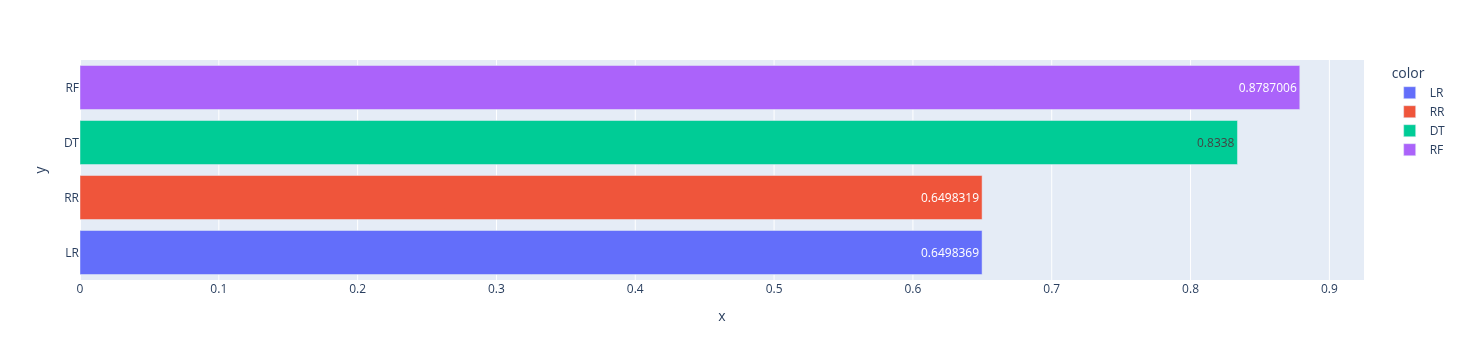

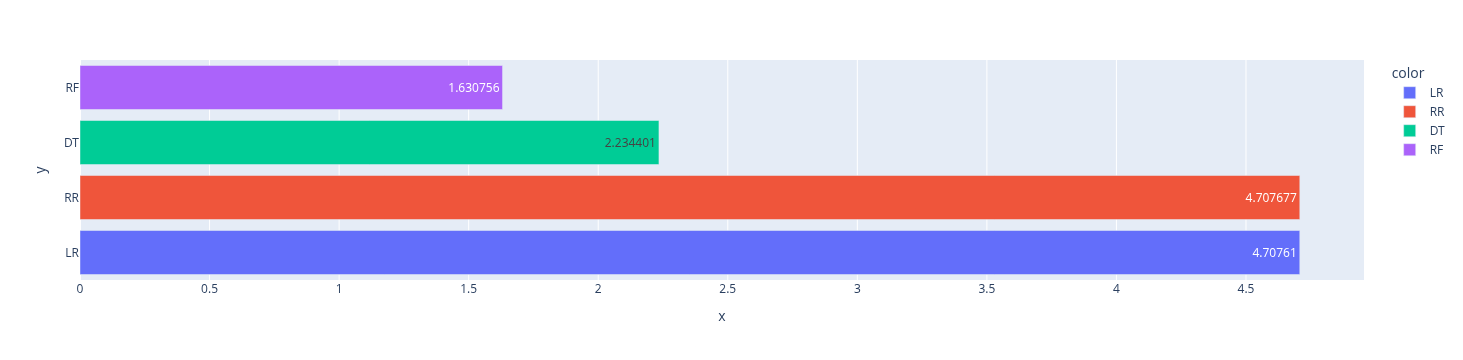

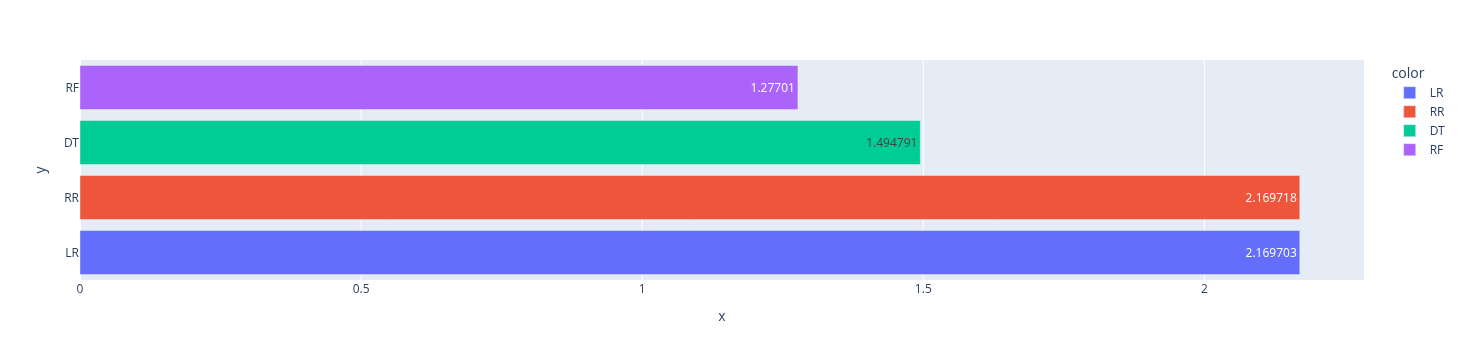

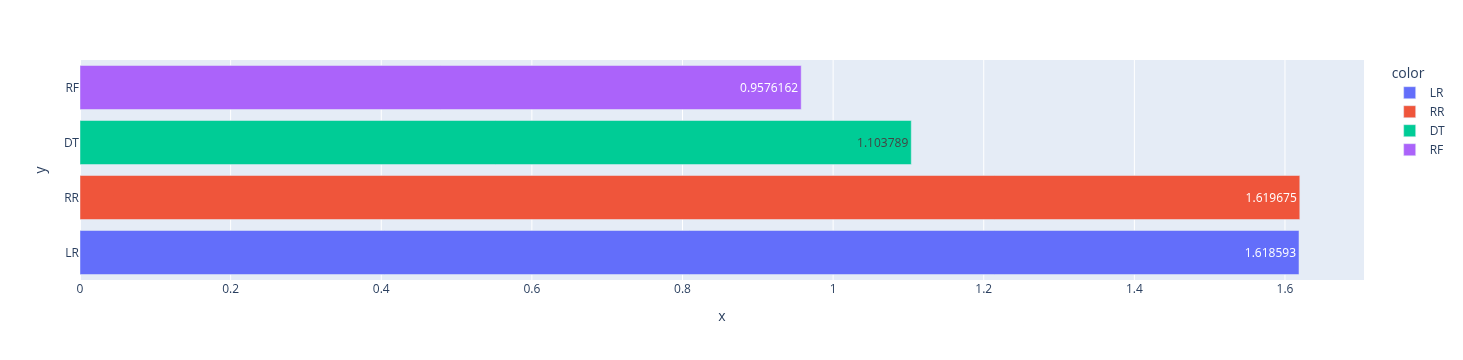

In [142]:
# comparaison des métriques
list_names = ["LR", "RR", "DT", "RF"]
list_r2 = [r2_lr, r2_rr, r2_dt, r2_rf]
list_mse = [mse_lr, mse_rr, mse_dt, mse_rf]
list_rmse= [rmse_lr, rmse_rr, rmse_dt, rmse_rf]
list_mae = [mae_lr, mae_rr, mae_dt, mae_rf]
list_final = [list_r2, list_mse, list_rmse, list_mae]

for i in range(4):
    fig = px.bar(y = list_names, x = list_final[i], color = list_names, text_auto = True)
    fig.show()

### <font color = 'teal'>Sélection et sauvegarde du modèle le plus performant<font>

In [143]:
# le modèle retenu est celui qui a le meilleur R2 sur les données de validation
models = {'LR': lr_model, 'RR': rr_model, 'DT': dt_model, 'RF': rf_model}
best_name = list_names[int(np.argmax(list_r2))]
best_model = models[best_name]
print(f"Modèle le plus performant : {best_name} (R2 validation = {max(list_r2):.4f})")

Modèle le plus performant : RF (R2 validation = 0.8787)


In [144]:
# télécharger le modèle le plus performant
jb.dump(best_model, "./models/prix_voiture_model.joblib")

['./models/prix_voiture_model.joblib']

### <font color = 'bisque'>Tester le modèle le plus performant<font>

In [145]:
# Evaluation du modèle retenu sur les données de test
y_pred_test = best_model.predict(x_test)
print(f"R2 (test): {r2_score(y_test, y_pred_test):.4f}, mae: {mean_absolute_error(y_test, y_pred_test):.2f}, rmse: {root_mean_squared_error(y_test, y_pred_test):.2f}")

R2 (test): 0.9046, mae: 0.84, rmse: 1.17


In [146]:
#  echantillon des données test
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# Prédictions
y_pred_10 = best_model.predict(x_test_10)
# Parcourir les prédictions
for i in range(10):
  print(f"Prédiction {i + 1} : {y_pred_10[i]:.2f} --Réel : {y_test_10[i]:.2f}")

Prédiction 1 : 12.54 --Réel : 12.51
Prédiction 2 : 5.40 --Réel : 7.25
Prédiction 3 : 12.12 --Réel : 8.38
Prédiction 4 : 6.74 --Réel : 5.59
Prédiction 5 : 7.38 --Réel : 7.61
Prédiction 6 : 8.43 --Réel : 8.39
Prédiction 7 : 5.40 --Réel : 4.93
Prédiction 8 : 5.41 --Réel : 4.79
Prédiction 9 : 4.65 --Réel : 4.65
Prédiction 10 : 9.33 --Réel : 8.96
